# Olist e-commerce analysis

Olist is a Brazilian marketplace that connects small sellers to large online stores. This notebook uses the public Olist dataset (about 99,000 orders placed between September 2016 and October 2018) to answer five business questions:

1. How many orders are there, what happens to them, and how has volume changed over time?
2. Which product categories bring in the most revenue?
3. Do late deliveries get lower review scores?
4. What share of customers come back and order again?
5. How do revenue and delivery time vary by state?

The method is the same for each question: load the CSV files into a SQLite database, answer the question with a SQL query, draw a simple chart, and write down the finding in plain words.

## Setup

The raw CSV files sit in `data/` (downloaded from Kaggle, not uploaded to GitHub). The cell below copies each CSV into a table inside one SQLite database file, `data/olist.db`, so the tables can be joined with SQL.

In [1]:
import sqlite3                      # SQLite: a small database stored in a single file, built into Python
import pandas as pd                 # pandas: tables (DataFrames) in Python
import matplotlib.pyplot as plt     # matplotlib: charts
import os

os.makedirs("images", exist_ok=True)  # folder for saving charts used in the README

# Map a short table name to the CSV file it comes from
files = {
    "orders": "olist_orders_dataset",
    "customers": "olist_customers_dataset",
    "order_items": "olist_order_items_dataset",
    "payments": "olist_order_payments_dataset",
    "reviews": "olist_order_reviews_dataset",
    "products": "olist_products_dataset",
    "category_translation": "product_category_name_translation",
}

conn = sqlite3.connect("data/olist.db")   # opens the database file (creates it if missing)

for table, filename in files.items():
    # utf-8-sig removes a hidden character at the start of one of the files
    df = pd.read_csv(f"data/{filename}.csv", encoding="utf-8-sig")
    df.to_sql(table, conn, if_exists="replace", index=False)   # write the DataFrame as a SQL table
    print(f"{table:22s} {df.shape[0]:>7,} rows  {df.shape[1]:>2} columns")

def q(sql):
    """Run a SQL query and return the result as a pandas DataFrame."""
    return pd.read_sql(sql, conn)

orders                  99,441 rows   8 columns


customers               99,441 rows   5 columns


order_items            112,650 rows   7 columns


payments               103,886 rows   5 columns


reviews                 99,224 rows   7 columns


products                32,951 rows   9 columns
category_translation        71 rows   2 columns


In [2]:
# Shared chart style: light grid behind the data, no top/right box lines
BLUE, ORANGE, GRID, AXIS = "#2a78d6", "#eb6834", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": AXIS, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "font.size": 10,
})

## 1. Order overview

Every order has a status. Most should be `delivered`; the rest were cancelled, never shipped or are still in progress.

In [3]:
status = q("""
    SELECT order_status,
           COUNT(*) AS orders,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM orders), 2) AS pct
    FROM orders
    GROUP BY order_status
    ORDER BY orders DESC
""")
status

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


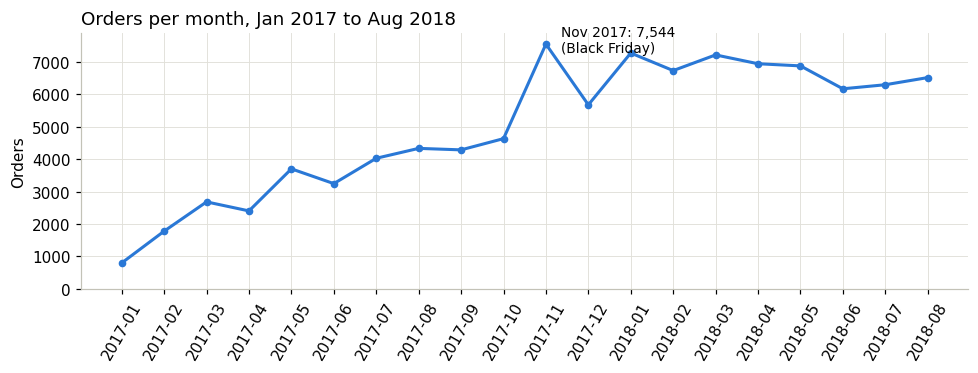

month,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08
orders,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512


In [4]:
# Orders per month. substr(..., 1, 7) keeps 'YYYY-MM' from the timestamp.
monthly = q("""
    SELECT substr(order_purchase_timestamp, 1, 7) AS month,
           COUNT(*) AS orders
    FROM orders
    GROUP BY month
    ORDER BY month
""")
# The first few months (2016) and the last two (Sep-Oct 2018) have almost no orders,
# because the dataset starts and ends there, so the chart uses Jan 2017 to Aug 2018.
monthly = monthly[(monthly.month >= "2017-01") & (monthly.month <= "2018-08")]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(monthly.month, monthly.orders, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_title("Orders per month, Jan 2017 to Aug 2018", loc="left")
ax.set_ylabel("Orders")
ax.set_ylim(0)
ax.tick_params(axis="x", rotation=60)
peak = monthly.loc[monthly.orders.idxmax()]
ax.annotate(f"Nov 2017: {peak.orders:,}\n(Black Friday)", (peak.month, peak.orders),
            xytext=(10, -5), textcoords="offset points", fontsize=9)
plt.tight_layout(); plt.savefig("images/orders_per_month.png"); plt.show()
monthly.set_index("month").T

**Finding.** There are 99,441 orders and 97.0% of them were delivered; only 0.6% were cancelled. Monthly orders grew from 800 in January 2017 to between 6,000 and 7,300 a month through 2018, roughly an eight-fold increase. The single biggest month was November 2017 (7,544 orders), which lines up with Black Friday. Volume levelled off in 2018 rather than continuing to climb.

## 2. Revenue by product category

Revenue here means the sum of item prices (`order_items.price`), not including freight, for delivered orders only. Category names are in Portuguese in `products`, so I join `category_translation` to get English names.

The join path is: `order_items` → `orders` (to keep delivered orders) → `products` (to get the category) → `category_translation` (to get the English name).

In [5]:
categories = q("""
    SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
           ROUND(SUM(oi.price), 0)       AS revenue,
           COUNT(DISTINCT oi.order_id)   AS orders
    FROM order_items oi
    JOIN orders o                    ON o.order_id = oi.order_id
    LEFT JOIN products p             ON p.product_id = oi.product_id
    LEFT JOIN category_translation t ON t.product_category_name = p.product_category_name
    WHERE o.order_status = 'delivered'
    GROUP BY category
    ORDER BY revenue DESC
""")
total_revenue = categories.revenue.sum()
categories["share_pct"] = (100 * categories.revenue / total_revenue).round(1)
print(f"Total revenue from delivered orders: R$ {total_revenue:,.0f} across {len(categories)} categories")
top10 = categories.head(10)
top10

Total revenue from delivered orders: R$ 13,221,499 across 74 categories


,category,revenue,orders,share_pct
0,health_beauty,1233132.0,8647,9.3
1,watches_gifts,1166177.0,5495,8.8
2,bed_bath_table,1023435.0,9272,7.7
3,sports_leisure,954853.0,7530,7.2
4,computers_accessories,888725.0,6530,6.7
5,furniture_decor,711928.0,6307,5.4
6,housewares,615629.0,5743,4.7
7,cool_stuff,610204.0,3559,4.6
8,auto,578967.0,3810,4.4
9,toys,471286.0,3804,3.6


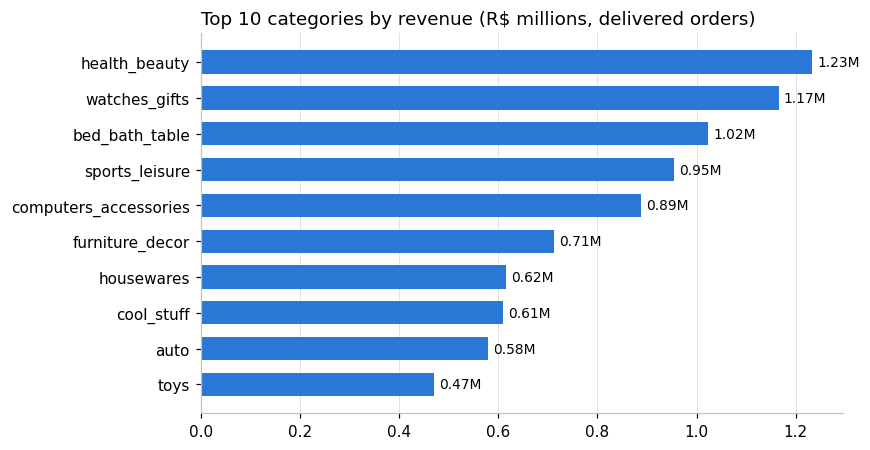

Top 10 share of total revenue: 62.4%


In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
d = top10.iloc[::-1]                         # reverse so the largest bar is at the top
ax.barh(d.category, d.revenue / 1e6, color=BLUE, height=0.65)
for y, v in enumerate(d.revenue / 1e6):
    ax.text(v + 0.01, y, f"{v:.2f}M", va="center", fontsize=9)
ax.set_title("Top 10 categories by revenue (R$ millions, delivered orders)", loc="left")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/top_categories.png"); plt.show()
print(f"Top 10 share of total revenue: {top10.share_pct.sum():.1f}%")

**Finding.** Delivered orders brought in about R$ 13.2 million in item revenue across 74 categories. Health and beauty is the largest at R$ 1.23M, followed closely by watches and gifts (R$ 1.17M) and bed, bath and table (R$ 1.02M). The top 10 categories make up 62.4% of revenue. Watches and gifts reaches second place with far fewer orders than bed, bath and table (5,495 against 9,272), so its items are more expensive on average.

## 3. Do late deliveries get lower review scores?

This is the main question of the project. An order counts as **late** if the customer received it on a later calendar day than the estimated delivery date that Olist showed at checkout. I compare dates rather than full timestamps because the estimate is always given as midnight.

A few orders have more than one review, so I first average the score per order, then join it to the delivery status.

In [7]:
late_vs_ontime = q("""
    WITH delivery AS (
        SELECT order_id,
               CASE WHEN date(order_delivered_customer_date) > date(order_estimated_delivery_date)
                    THEN 'late' ELSE 'on time' END AS delivery_status
        FROM orders
        WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
    ),
    review AS (
        SELECT order_id, AVG(review_score) AS score
        FROM reviews
        GROUP BY order_id
    )
    SELECT delivery_status,
           COUNT(*)                                                  AS orders,
           ROUND(AVG(score), 2)                                      AS avg_score,
           ROUND(100.0 * AVG(CASE WHEN score <= 2 THEN 1 ELSE 0 END), 1) AS pct_1_or_2_stars,
           ROUND(100.0 * AVG(CASE WHEN score = 5  THEN 1 ELSE 0 END), 1) AS pct_5_stars
    FROM delivery JOIN review USING (order_id)
    GROUP BY delivery_status
""")
late_vs_ontime["pct_of_orders"] = (100 * late_vs_ontime.orders / late_vs_ontime.orders.sum()).round(1)
late_vs_ontime

,delivery_status,orders,avg_score,pct_1_or_2_stars,pct_5_stars,pct_of_orders
0,late,6381,2.27,62.4,16.5,6.7
1,on time,89443,4.29,9.2,62.2,93.3


In [8]:
# Does it get worse the later the order is? Group by days late.
by_days_late = q("""
    WITH delivery AS (
        SELECT order_id,
               julianday(date(order_delivered_customer_date))
             - julianday(date(order_estimated_delivery_date)) AS days_late
        FROM orders
        WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
    ),
    review AS (SELECT order_id, AVG(review_score) AS score FROM reviews GROUP BY order_id)
    SELECT CASE WHEN days_late <= 0  THEN '1. on time'
                WHEN days_late <= 3  THEN '2. 1-3 days late'
                WHEN days_late <= 7  THEN '3. 4-7 days late'
                WHEN days_late <= 14 THEN '4. 8-14 days late'
                ELSE '5. 15+ days late' END AS bucket,
           COUNT(*) AS orders,
           ROUND(AVG(score), 2) AS avg_score
    FROM delivery JOIN review USING (order_id)
    GROUP BY bucket ORDER BY bucket
""")
by_days_late["bucket"] = by_days_late.bucket.str[3:]   # drop the '1. ' sort prefix
by_days_late

,bucket,orders,avg_score
0,on time,89443,4.29
1,1-3 days late,1852,3.29
2,4-7 days late,1748,2.11
3,8-14 days late,1446,1.67
4,15+ days late,1335,1.73


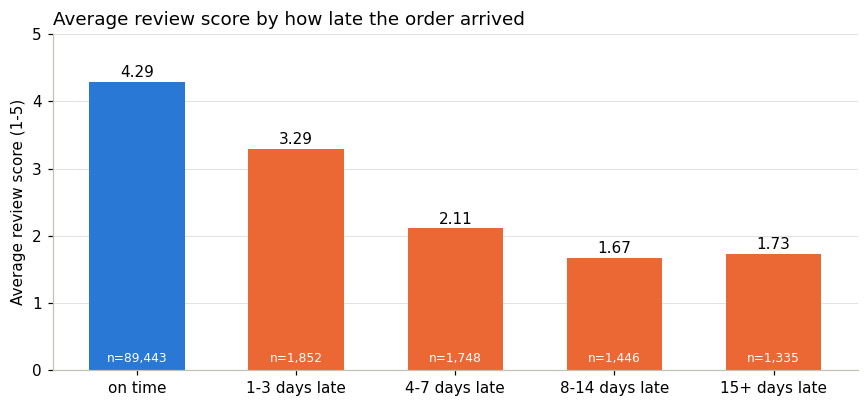

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [BLUE] + [ORANGE] * (len(by_days_late) - 1)   # blue = on time, orange = late
ax.bar(by_days_late.bucket, by_days_late.avg_score, color=colors, width=0.6)
for x, (v, n) in enumerate(zip(by_days_late.avg_score, by_days_late.orders)):
    ax.text(x, v + 0.07, f"{v:.2f}", ha="center", fontsize=10)
    ax.text(x, 0.12, f"n={n:,}", ha="center", fontsize=8, color="white")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score (1-5)")
ax.set_title("Average review score by how late the order arrived", loc="left")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.savefig("images/review_by_lateness.png"); plt.show()

**Finding.** 6.7% of delivered orders (6,381 of 95,824 with a review) arrived after the estimated date. Their average review score is 2.27 out of 5, against 4.29 for on-time orders. 62% of late orders got 1 or 2 stars compared with 9% of on-time orders. The drop starts immediately: even 1 to 3 days late pulls the average down to 3.29, and beyond a week late it falls below 2. For Olist this means late delivery is the clearest driver of bad reviews in the data, and setting realistic delivery estimates (or warning customers early) is likely to protect ratings more than almost anything else.

*Caveat:* this shows a strong association, not proof of cause. Late orders might also differ in other ways (region, product type), but the size of the gap and the steady drop with each extra day make lateness the most likely explanation.

## 4. Repeat customers

The `customer_id` column in `orders` is **new for every order**, so counting it would make every customer look like a one-time buyer. `customer_unique_id` in the `customers` table identifies the actual person, so I count orders per `customer_unique_id`.

In [10]:
repeat = q("""
    WITH per_person AS (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o
        JOIN customers c ON c.customer_id = o.customer_id
        GROUP BY c.customer_unique_id
    )
    SELECT COUNT(*)                                        AS customers,
           SUM(n_orders > 1)                               AS repeat_customers,
           ROUND(100.0 * SUM(n_orders > 1) / COUNT(*), 2)  AS repeat_pct,
           MAX(n_orders)                                   AS max_orders_one_person
    FROM per_person
""")
repeat

,customers,repeat_customers,repeat_pct,max_orders_one_person
0,96096,2997,3.12,17


In [11]:
dist = q("""
    WITH per_person AS (
        SELECT c.customer_unique_id, COUNT(DISTINCT o.order_id) AS n_orders
        FROM orders o JOIN customers c ON c.customer_id = o.customer_id
        GROUP BY c.customer_unique_id
    )
    SELECT CASE WHEN n_orders >= 4 THEN '4+' ELSE CAST(n_orders AS TEXT) END AS orders_per_customer,
           COUNT(*) AS customers
    FROM per_person GROUP BY 1 ORDER BY 1
""")
dist["pct"] = (100 * dist.customers / dist.customers.sum()).round(2)
dist

,orders_per_customer,customers,pct
0,1,93099,96.88
1,2,2745,2.86
2,3,203,0.21
3,4+,49,0.05


**Finding.** 96,096 different people placed orders, and only 2,997 of them (3.1%) ordered more than once. Almost all revenue comes from first-time buyers. For a marketplace this is a weak point: the business depends on constantly finding new customers. A loyalty offer or follow-up emails after a good delivery would be the obvious things to test. (Some of this is also because the data only covers about two years.)

## 5. Geography: revenue and delivery time by state

Revenue per state comes from `order_items` joined to the customer's state. Delivery time is the number of days from purchase to the customer receiving the order. I calculate delivery time **per order** in a separate step, because joining to `order_items` first would count an order with three items three times.

In [12]:
states = q("""
    WITH rev AS (
        SELECT o.order_id, SUM(oi.price) AS order_revenue
        FROM orders o JOIN order_items oi ON oi.order_id = o.order_id
        WHERE o.order_status = 'delivered'
        GROUP BY o.order_id
    )
    SELECT c.customer_state AS state,
           COUNT(*)                         AS orders,
           ROUND(SUM(r.order_revenue), 0)   AS revenue,
           ROUND(AVG(julianday(o.order_delivered_customer_date)
                   - julianday(o.order_purchase_timestamp)), 1) AS avg_delivery_days
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    JOIN rev r       ON r.order_id = o.order_id
    WHERE o.order_delivered_customer_date IS NOT NULL
    GROUP BY state
    ORDER BY revenue DESC
""")
states["revenue_share_pct"] = (100 * states.revenue / states.revenue.sum()).round(1)
overall_days = q("""
    SELECT ROUND(AVG(julianday(order_delivered_customer_date) - julianday(order_purchase_timestamp)), 1) AS d
    FROM orders WHERE order_status = 'delivered' AND order_delivered_customer_date IS NOT NULL
""").d[0]
print("Average delivery time, all delivered orders:", overall_days, "days")
states

Average delivery time, all delivered orders: 12.6 days


,state,orders,revenue,avg_delivery_days,revenue_share_pct
0,SP,40494,5066563.0,8.8,38.3
1,RJ,12350,1759651.0,15.3,13.3
2,MG,11354,1552482.0,12.0,11.7
3,RS,5344,728718.0,15.3,5.5
4,PR,4923,666064.0,12.0,5.0
5,SC,3546,507012.0,15.0,3.8
6,BA,3256,493584.0,19.3,3.7
7,DF,2080,296498.0,13.0,2.2
8,GO,1957,282837.0,15.6,2.1
9,ES,1995,268643.0,15.8,2.0


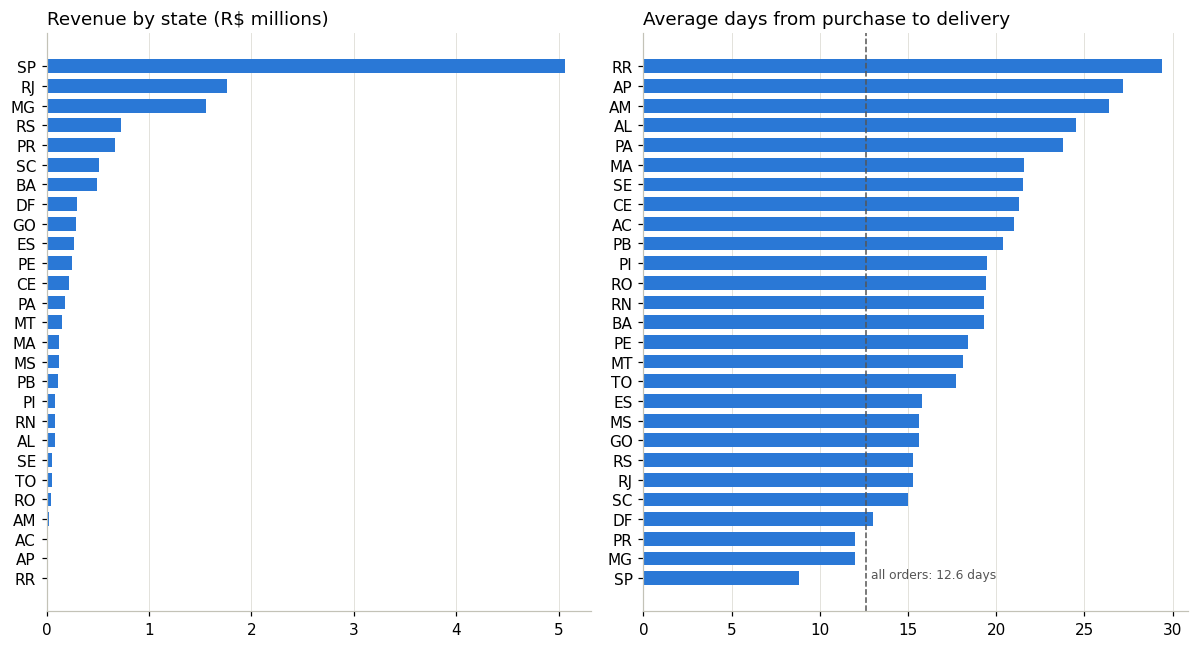

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6))
d = states.iloc[::-1]
axes[0].barh(d.state, d.revenue / 1e6, color=BLUE, height=0.7)
axes[0].set_title("Revenue by state (R$ millions)", loc="left")
axes[0].grid(axis="y", visible=False)

d2 = states.sort_values("avg_delivery_days")
axes[1].barh(d2.state, d2.avg_delivery_days, color=BLUE, height=0.7)
axes[1].axvline(overall_days, color="#555", linewidth=1, linestyle="--")
axes[1].text(overall_days + 0.3, 0, f"all orders: {overall_days} days", fontsize=8, color="#555")
axes[1].set_title("Average days from purchase to delivery", loc="left")
axes[1].grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig("images/states.png"); plt.show()

**Finding.** São Paulo state (SP) alone accounts for 38.3% of revenue, and SP, Rio de Janeiro and Minas Gerais together make up 63.3%. SP also gets the fastest deliveries at 8.8 days on average, compared with 12.6 days across all orders. Delivery times rise steadily with distance from the south-east: northern states such as Roraima (29.4 days), Amapá (27.2) and Amazonas (26.4) wait about three times as long as SP customers. Most sellers are based in the south-east, so the far north is both the smallest market and the worst served. Given the finding in section 3, slow delivery in these states is probably also costing Olist reviews there.

## Summary

| Question | Answer |
|---|---|
| Order volume | 99,441 orders, 97.0% delivered; monthly orders rose about eight-fold from Jan 2017 and peaked at 7,544 in Nov 2017 |
| Top categories | Health and beauty (R$ 1.23M), watches and gifts (R$ 1.17M), bed, bath and table (R$ 1.02M); top 10 = 62.4% of R$ 13.2M |
| Late delivery and reviews | 6.7% of orders arrived late; average score 2.27 vs 4.29 on time; 62% of late orders got 1-2 stars vs 9% |
| Repeat customers | Only 3.1% of 96,096 customers ordered more than once |
| Geography | SP is 38.3% of revenue and fastest (8.8 days); northern states wait 26-29 days |

In [14]:
conn.close()